# Live Conversation Moderator

English conversation moderation · NLP group assignment

The first code cell checks the Colab runtime and reports the available GPU.

In [ ]:
from pathlib import Path
import shutil
import subprocess

assert Path('/content').is_dir(), 'Expected a Colab runtime'
print('Colab runtime check passed.')
if shutil.which('nvidia-smi'):
    subprocess.run(['nvidia-smi', '--query-gpu=name', '--format=csv,noheader'], check=True)
else:
    print('GPU: none attached')

Colab runtime check passed.
GPU: none attached


## Phase 2 — Data understanding

**Source:** Wulczyn, Thain, and Dixon (2016), *Wikipedia Talk Labels: Personal Attacks*, [Figshare v6](https://doi.org/10.6084/m9.figshare.4054689.v6), released under CC0. The [Wikimedia data release](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release) documents the sampling and annotation schema.

The corpus contains English Wikipedia talk-page comments sampled at random and around user blocks. It is a starting point for a model that flags potential personal attacks for human review. Written Wikipedia comments differ from live speech and automatic transcripts, so offline results on this corpus cannot establish live accuracy.

The files join on `rev_id`. Each comment is positive if a strict majority of annotators marked `attack=1`. An exact tie maps to class 0 under this rule. The published split is retained as metadata. The assignment's stratified 80/20 split will be built in the preparation phase.

In [ ]:
from datetime import datetime, timezone
import hashlib
from pathlib import Path

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

DATA_DIR = Path("/content/wikidetox")
DATA_DIR.mkdir(exist_ok=True)
DATA_FILES = {
    "attack_annotated_comments.tsv": (7554634, "7e39135b410eaed85c7ffec85cf829fd"),
    "attack_annotations.tsv": (7554637, "c1621e0451236eb3eea9c8f7df77f4b7"),
}

def file_md5(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "md5").hexdigest()

retry = Retry(total=2, backoff_factor=1, status_forcelist=(429, 500, 502, 503, 504))
with requests.Session() as session:
    session.mount("https://", HTTPAdapter(max_retries=retry))
    for filename, (file_id, digest) in DATA_FILES.items():
        target = DATA_DIR / filename
        if target.is_file() and file_md5(target) == digest:
            print(f"{filename}: verified cached file ({target.stat().st_size:,} bytes)")
            continue

        pending = target.with_suffix(".partial")
        url = f"https://ndownloader.figshare.com/files/{file_id}"
        try:
            with session.get(url, stream=True, timeout=(15, 30)) as response:
                response.raise_for_status()
                with pending.open("wb") as stream:
                    for chunk in response.iter_content(chunk_size=256 * 1024):
                        stream.write(chunk)
            if file_md5(pending) != digest:
                raise ValueError(f"Checksum mismatch for {filename}")
            pending.replace(target)
        finally:
            pending.unlink(missing_ok=True)
        print(f"{filename}: downloaded and verified ({target.stat().st_size:,} bytes)")

print(f"Source: Figshare v6 · verified {datetime.now(timezone.utc):%Y-%m-%d %H:%M UTC}")

attack_annotated_comments.tsv: verified cached file (58,121,115 bytes)
attack_annotations.tsv: verified cached file (46,760,112 bytes)
Source: Figshare v6 · verified 2026-11-17 15:26 UTC


In [ ]:
import csv

from IPython.display import display
import pandas as pd

comments = pd.read_csv(
    DATA_DIR / "attack_annotated_comments.tsv",
    sep="\t",
    quoting=csv.QUOTE_NONE,
    keep_default_na=False,
    dtype={"rev_id": "int64", "comment": "string"},
)
votes = pd.read_csv(
    DATA_DIR / "attack_annotations.tsv",
    sep="\t",
    usecols=["rev_id", "worker_id", "attack"],
    dtype={"rev_id": "int64", "worker_id": "int64", "attack": "int8"},
)

assert comments["rev_id"].is_unique, "Unexpected repeated revision IDs"
assert votes["attack"].isin([0, 1]).all(), "Attack votes must be binary"
assert not votes.duplicated(["rev_id", "worker_id"]).any(), "Repeated worker vote"

per_comment = votes.groupby("rev_id")["attack"].agg(attack_votes="sum", ratings="size")
missing_labels = pd.Index(comments["rev_id"]).difference(per_comment.index)
unknown_revisions = per_comment.index.difference(comments["rev_id"])
assert missing_labels.empty and unknown_revisions.empty, "Unmatched revision IDs"

per_comment["attack_share"] = per_comment["attack_votes"] / per_comment["ratings"]
per_comment["label"] = (2 * per_comment["attack_votes"] > per_comment["ratings"]).astype("int8")
data = comments.merge(per_comment, left_on="rev_id", right_index=True, validate="one_to_one")
assert len(data) >= 1000 and data["label"].nunique() == 2

raw = data["comment"].str.strip()
empty = raw.eq("")
usable_raw = raw[~empty]
conflicting_texts = data.loc[~empty].groupby(usable_raw)["label"].nunique().gt(1).sum()

summary = pd.Series({
    "Comments": len(data),
    "Individual annotation votes": len(votes),
    "Median votes per comment": int(data["ratings"].median()),
    "Exact voting ties": int((2 * data["attack_votes"] == data["ratings"]).sum()),
    "Empty or whitespace-only comments": int(empty.sum()),
    "Extra exact copies among non-empty comments": int(usable_raw.duplicated().sum()),
    "Distinct non-empty texts with conflicting labels": int(conflicting_texts),
}, name="Count")
display(summary.to_frame().style.format("{:,}"))

CLASS_NAMES = {0: "No personal attack", 1: "Personal attack"}
class_counts = data["label"].value_counts().reindex([0, 1])
class_table = pd.DataFrame({
    "Comments": class_counts,
    "Share": class_counts / len(data),
}).rename(index=CLASS_NAMES)
display(class_table.style.format({"Comments": "{:,}", "Share": "{:.2%}"}))

,Count
Comments,"115,864"
Individual annotation votes,"1,365,217"
Median votes per comment,10
Exact voting ties,"1,987"
Empty or whitespace-only comments,0
Extra exact copies among non-empty comments,269
Distinct non-empty texts with conflicting labels,11


,Comments,Share
label,,
No personal attack,"102,274",88.27%
Personal attack,"13,590",11.73%


Words             Characters              
                   median  mean   max     median   mean    max
label                                                         
No personal attack   37.0  71.4  2500      213.0  418.5  10000
Personal attack      24.0  61.1  2832      128.0  348.4  10000

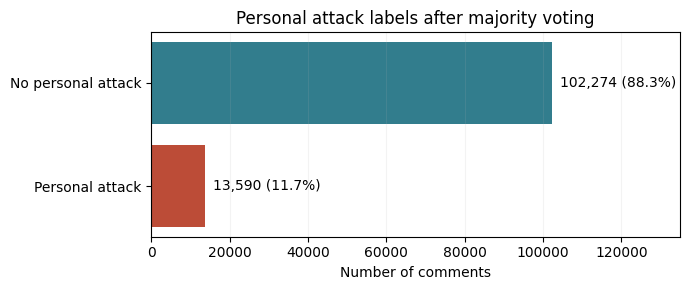

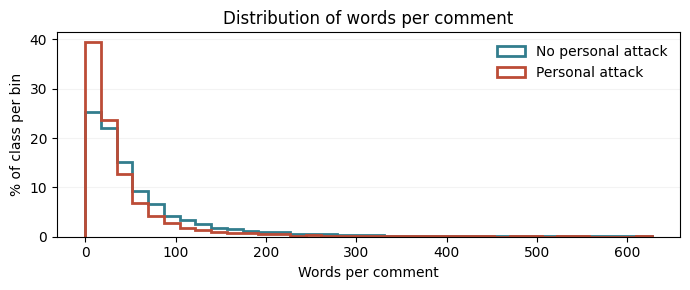

Words: the plot omits values above 627 (pooled 99th percentile).


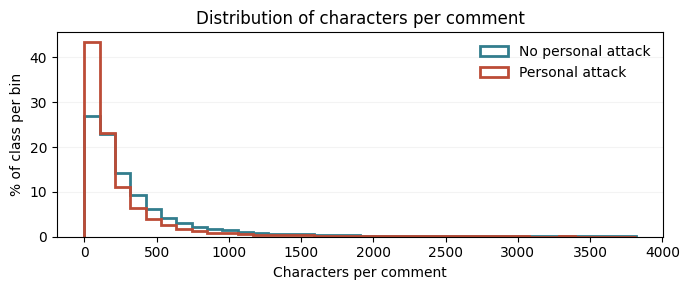

Characters: the plot omits values above 3,816 (pooled 99th percentile).


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Restore the exported whitespace markers before measuring raw text lengths.
length_text = (
    data["comment"]
    .str.replace("NEWLINE_TOKEN", "\n", regex=False)
    .str.replace("TAB_TOKEN", "\t", regex=False)
    .str.strip()
)
lengths = pd.DataFrame({
    "Words": length_text.str.count(r"\S+"),
    "Characters": length_text.str.len(),
}, index=data.index)

length_summary = lengths.groupby(data["label"]).agg(["median", "mean", "max"])
display(length_summary.rename(index=CLASS_NAMES).round(1))

colors = ("#327d8d", "#bc4c37")
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(list(CLASS_NAMES.values()), class_counts, color=colors)
ax.bar_label(
    bars,
    labels=[f"{count:,} ({count / len(data):.1%})" for count in class_counts],
    padding=6,
)
ax.set(xlim=(0, class_counts.max() * 1.32), xlabel="Number of comments",
       title="Personal attack labels after majority voting")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.15)
fig.tight_layout()
plt.show()

for metric in lengths:
    limit = int(np.ceil(lengths[metric].quantile(0.99)))
    bins = np.linspace(0, limit, 37)
    fig, ax = plt.subplots(figsize=(7, 3))
    for label, color in zip(CLASS_NAMES, colors):
        values = lengths.loc[data["label"].eq(label), metric]
        ax.hist(
            values, bins=bins, weights=np.full(len(values), 100 / len(values)),
            histtype="step", linewidth=2, color=color, label=CLASS_NAMES[label],
        )
    ax.set(xlabel=f"{metric} per comment",
           ylabel="% of class per bin", title=f"Distribution of {metric.lower()} per comment")
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=0.15)
    fig.tight_layout()
    plt.show()
    print(f"{metric}: the plot omits values above {limit:,} (pooled 99th percentile).")

In [ ]:
import re

raw_comments = data["comment"]
# Record only the matched pattern. Full URLs and tag attributes can contain personal data.
noise_patterns = {
    "Exported newline/tab marker": (r"NEWLINE_TOKEN|TAB_TOKEN", "match"),
    "URL": (r"(?i)\b(?:https?://|www\.)[^\s<]+", "redact"),
    "HTML-like tag": (r"(?i)</?[a-z][a-z0-9:-]*(?:\s[^<>]*)?\s*/?>", "tag"),
    "Common contraction": (r"(?i)\b(?:don['’]t|can['’]t|won['’]t|isn['’]t|i['’]m|we['’]re)\b", "match"),
    "Chat abbreviation": (r"(?i)\b(?:idk|imo|imho|btw|lol|pls|plz|thx)\b", "match"),
    "Candidate spelling error": (r"(?i)\b(?:teh|recieve|seperate|definately|wierd|occured|alot)\b", "match"),
    "Repeated punctuation": (r"[!?]{2,}|\.{3,}", "match"),
    "Non-ASCII characters": (r"[^\x00-\x7f]", "omit"),
}

def pattern_example(pattern, policy, comment):
    if policy == "redact":
        return "[URL redacted]"
    if policy == "omit":
        return "—"
    match = re.search(pattern, comment).group()
    if policy == "tag":
        return re.match(r"</?[a-zA-Z][a-zA-Z0-9:-]*", match).group() + ">"
    return match[:24]

rows = []
for feature, (pattern, policy) in noise_patterns.items():
    mask = raw_comments.str.contains(pattern, na=False, regex=True)
    count = int(mask.sum())
    example = pattern_example(pattern, policy, raw_comments.loc[mask.idxmax()]) if count else "—"
    rows.append((feature, count, round(100 * count / len(data), 2), example))

noise_summary = pd.DataFrame(rows, columns=["Pattern", "Comments", "Corpus share (%)", "Matched example"])
display(noise_summary.set_index("Pattern"))

domain_words = ["page", "talk", "article", "edit", "wikipedia"]
domain_counts = {
    word: int(raw_comments.str.contains(rf"\b{word}\b", case=False, regex=True).sum())
    for word in domain_words
}
display(pd.Series(domain_counts, name="Comments containing term").sort_values(ascending=False).to_frame())

,Comments,Corpus share (%),Matched example
Pattern,,,
Exported newline/tab marker,105243,90.83,NEWLINE_TOKEN
URL,3338,2.88,[URL redacted]
HTML-like tag,1,0.00,<Is>
Common contraction,24598,21.23,don't
Chat abbreviation,1836,1.58,BTW
Candidate spelling error,621,0.54,seperate
Repeated punctuation,13422,11.58,...
Non-ASCII characters,9462,8.17,—


,Comments containing term
article,21577
page,18579
wikipedia,17985
talk,10822
edit,8873


### What the audit means for the model

- **Class imbalance.** The raw corpus contains 115,864 comments and 1,365,217 votes. The positive class is 13,590 comments (11.73%). Predicting the majority label always would already score 88.27% accuracy on this corpus. Report macro F1, positive-class precision and recall, and accuracy in the model comparison.
- **Length and domain.** The median is 24 words for positive comments and 37 for negative comments. Both classes have long tails, and terms such as “article” and “Wikipedia” reflect the source domain. Test separately on short spoken English and transcripts.
- **Text preparation.** Restore export markers before tokenization, preserve negation when expanding contractions, and handle URLs and repeated punctuation consistently. The tag detector found only one tag-shaped string (`<Is>`), consistent with markup having already been stripped from the released text. The spelling screen checks a short list of variants and only estimates their frequency.
- **Label quality and duplicates.** Strict majority yields 1,987 ties mapped to class 0. There are 269 extra exact text copies after trimming and 11 distinct text strings with conflicting labels. Resolve duplicates and label conflicts before assigning records to train and test. Keep the original annotation counts for auditing.

The next phase defines the text preprocessing function and the 80/20 stratified split.

## Phase 3 — Data preparation and feature extraction

The shared function restores export separators, normalizes Unicode and case, strips links and HTML, expands selected contractions and chat abbreviations, and produces word tokens. Word tokens make the features easy to inspect and let bigrams preserve local cues such as “not helpful” and “you are.” We retain stopwords to keep personal pronouns, negation and adjacent context, and retain particles such as “lah” and “ya” for the dialect audit.

We compare Snowball stemming with POS-aware WordNet lemmatization below. The shared baseline uses **Snowball stemming** to combine common inflections with low per-turn overhead and a compact deployment. It can produce shortened forms and merge distinct words, so the interface keeps the original utterance alongside its model text. Model quality will be measured on the held-out split.

In [ ]:
%%writefile nlp_pipeline.py
"""Shared word-level preprocessing for the personal attack classifier."""

from functools import lru_cache
import html
import re
import unicodedata

from nltk.stem import SnowballStemmer
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer


URL = re.compile(r"\b(?:https?://|www\.)[^\s<>]+")
HTML_TAG = re.compile(r"<!--[\s\S]*?-->|</?[a-z][a-z0-9:-]*(?:\s[^<>]*)?/?>")
WORD = re.compile(r"[^\W_]+(?:'[^\W_]+)*")
APOSTROPHES = str.maketrans({"’": "'", "‘": "'", "ʼ": "'"})
EXPANSIONS = {
    "can't": "can not",
    "cannot": "can not",
    "won't": "will not",
    "shan't": "shall not",
    "i'm": "i am",
    "you're": "you are",
    "we're": "we are",
    "they're": "they are",
    "i've": "i have",
    "you've": "you have",
    "we've": "we have",
    "they've": "they have",
    "idk": "i do not know",
    "btw": "by the way",
    "imo": "in my opinion",
    "imho": "in my humble opinion",
    "pls": "please",
    "plz": "please",
    "thx": "thanks",
}
NEGATIVE_CONTRACTION = re.compile(
    r"\b(do|does|did|is|are|was|were|have|has|had|could|should|would|must|might|need)n't\b"
)
KEEP_FORM = frozenset({"i", "you", "your", "yours", "no", "not", "nor", "never", "lah", "ya", "lol"})
STEMMER = SnowballStemmer("english")


def tokenize(text: str) -> list[str]:
    """Remove export noise and return normalized word tokens."""
    text = text.replace("NEWLINE_TOKEN", " ").replace("TAB_TOKEN", " ")
    text = unicodedata.normalize("NFKC", html.unescape(text)).translate(APOSTROPHES).casefold()
    text = HTML_TAG.sub(" ", text)
    text = URL.sub(" ", text)
    text = NEGATIVE_CONTRACTION.sub(r"\1 not", text)
    return [
        word
        for token in WORD.findall(text)
        for word in EXPANSIONS.get(token, token).split()
    ]


@lru_cache(maxsize=32_768)
def stem_word(word: str) -> str:
    if word in KEEP_FORM or not word.isascii() or not word.isalpha():
        return word
    return STEMMER.stem(word)


def preprocess_text(text: str) -> str:
    """Return the same model text used for deduplication and inference."""
    return " ".join(stem_word(word) for word in tokenize(text))


def make_vectorizer(
    ngram_range: tuple[int, int] = (1, 1),
    max_features: int | None = 50_000,
    min_df: int = 2,
) -> TfidfVectorizer:
    """Build an unfitted vectorizer for use inside a scikit-learn pipeline."""
    return TfidfVectorizer(
        preprocessor=preprocess_text,
        tokenizer=str.split,
        token_pattern=None,
        lowercase=False,
        stop_words=None,
        ngram_range=ngram_range,
        max_features=max_features,
        min_df=min_df,
        sublinear_tf=True,
        dtype=np.float32,
    )


Writing nlp_pipeline.py


In [ ]:
import nltk
import pandas as pd
from IPython.display import display
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer

from nlp_pipeline import KEEP_FORM, make_vectorizer, preprocess_text, tokenize

try:
    nltk.pos_tag(["example"])
except LookupError:
    nltk.download("averaged_perceptron_tagger_eng", quiet=True, raise_on_error=True)
try:
    wordnet.ensure_loaded()
except LookupError:
    nltk.download("wordnet", quiet=True, raise_on_error=True)
    wordnet.ensure_loaded()

pos_map = {"J": "a", "N": "n", "V": "v", "R": "r"}
lemmatizer = WordNetLemmatizer()

def pos_aware_lemmas(tokens):
    result = []
    for token, tag in nltk.pos_tag(tokens):
        pos = pos_map.get(tag[0])
        if pos and token not in KEEP_FORM and token.isascii() and token.isalpha():
            token = lemmatizer.morphy(token, pos) or token
        result.append(token)
    return " ".join(result)

examples = [
    "I don’t agree with these policies.",
    "You’re blaming the students, lah.",
    "These uniforms look expensive, IMO.",
    "NEWLINE_TOKEN <b>We’re discussing prices</b>: https://example.com TAB_TOKEN",
    "I NEVER said that, ya!",
]

comparison = pd.DataFrame([
    {
        "Original": text,
        "Clean word tokens": " ".join(tokenize(text)),
        "Snowball stemming (selected)": preprocess_text(text),
        "POS-aware WordNet": pos_aware_lemmas(tokenize(text)),
    }
    for text in examples
])
display(comparison)

assert tokenize("<b>YOU</b>NEWLINE_TOKENCan’t ignore this, lah! WWW.example.com TAB_TOKEN idk") == [
    "you", "can", "not", "ignore", "this", "lah", "i", "do", "not", "know"
]
assert preprocess_text("TAB_TOKEN <!-- note --> https://example.com!!!") == ""
assert preprocess_text("You are not listening") == preprocess_text("you're NOT listening.")
assert preprocess_text("you are helpful") != preprocess_text("you are not helpful")
assert "never said" in make_vectorizer((1, 2)).build_analyzer()("I never said that")
print("Cleaning, negation, dialect tokens and adjacent-word checks passed.")

,Original,Clean word tokens,Snowball stemming (selected),POS-aware WordNet
0,I don’t agree with these policies.,i do not agree with these policies,i do not agre with these polici,i do not agree with these policy
1,"You’re blaming the students, lah.",you are blaming the students lah,you are blame the student lah,you be blame the student lah
2,"These uniforms look expensive, IMO.",these uniforms look expensive in my opinion,these uniform look expens in my opinion,these uniform look expensive in my opinion
3,NEWLINE_TOKEN <b>We’re discussing prices</b>: ...,we are discussing prices,we are discuss price,we be discuss price
4,"I NEVER said that, ya!",i never said that ya,i never said that ya,i never say that ya


Cleaning, negation, dialect tokens and adjacent-word checks passed.


In [ ]:
from math import ceil

from sklearn.model_selection import train_test_split

SEED = 42
prepared = data[["rev_id", "comment", "label", "ratings"]].copy()
prepared["model_text"] = prepared["comment"].map(preprocess_text)
nonempty = prepared.loc[prepared["model_text"].ne("")]
empty_count = len(prepared) - len(nonempty)

labels_per_text = nonempty.groupby("model_text", sort=False)["label"].transform("nunique")
conflicting = nonempty.loc[labels_per_text.gt(1)]
consistent = nonempty.loc[labels_per_text.eq(1)]

# Keep the row with the most ratings per identical model input; ties use the smallest ID.
deduplicated = (
    consistent.sort_values(["ratings", "rev_id"], ascending=[False, True])
    .drop_duplicates("model_text")
    .sort_values("rev_id")
    .reset_index(drop=True)
)
copies_removed = len(consistent) - len(deduplicated)
assert len(prepared) == empty_count + len(conflicting) + copies_removed + len(deduplicated)
assert len(deduplicated) >= 1000 and deduplicated["label"].nunique() == 2

train, test = train_test_split(
    deduplicated, test_size=0.20, stratify=deduplicated["label"], random_state=SEED
)
X_train, y_train = train["comment"], train["label"]
X_test, y_test = test["comment"], test["label"]

assert set(train["rev_id"]).isdisjoint(test["rev_id"])
assert set(train["model_text"]).isdisjoint(test["model_text"])
assert len(test) == ceil(0.20 * len(deduplicated))
assert abs(y_train.mean() - y_test.mean()) < 0.001

data_audit = pd.Series({
    "Original labelled comments": len(prepared),
    "Empty after preprocessing": empty_count,
    "Conflicting model-text groups": conflicting["model_text"].nunique(),
    "Rows excluded for conflicting labels": len(conflicting),
    "Extra same-label copies removed": copies_removed,
    "Unique labelled model inputs": len(deduplicated),
}, name="Rows or groups")
display(data_audit.to_frame())

split_summary = pd.DataFrame([
    {
        "Partition": name,
        "Total": len(partition),
        "No personal attack": int(partition["label"].eq(0).sum()),
        "Personal attack": int(partition["label"].eq(1).sum()),
        "Attack share (%)": round(100 * partition["label"].mean(), 2),
    }
    for name, partition in (("Train", train), ("Test (held out)", test))
]).set_index("Partition")
display(split_summary)
print(f"Stratified 80/20 split (seed {SEED}). No overlapping revision IDs or exact model inputs.")

,Rows or groups
Original labelled comments,115864
Empty after preprocessing,36
Conflicting model-text groups,49
Rows excluded for conflicting labels,116
Extra same-label copies removed,1108
Unique labelled model inputs,114604


,Total,No personal attack,Personal attack,Attack share (%)
Partition,,,,
Train,91683,80969,10714,11.69
Test (held out),22921,20242,2679,11.69


Stratified 80/20 split (seed 42). No overlapping revision IDs or exact model inputs.


In [ ]:
from time import perf_counter

# Compare the feature representations under the same budget, using the training split only.
feature_rows = []
for name, ngrams in (("Unigrams", (1, 1)), ("Unigrams + bigrams", (1, 2))):
    vectorizer = make_vectorizer(ngram_range=ngrams)
    start = perf_counter()
    matrix = vectorizer.fit_transform(X_train)
    fit_seconds = perf_counter() - start
    features = vectorizer.get_feature_names_out()
    feature_rows.append({
        "Representation": name,
        "Training rows": matrix.shape[0],
        "Features": matrix.shape[1],
        "Bigram features": sum(" " in feature for feature in features),
        "Nonzero entries": matrix.nnz,
        "Fit + transform (s)": round(fit_seconds, 2),
    })
    del vectorizer, matrix

feature_comparison = pd.DataFrame(feature_rows).set_index("Representation")
assert feature_comparison.loc["Unigrams", "Bigram features"] == 0
assert feature_comparison.loc["Unigrams + bigrams", "Bigram features"] > 0
display(feature_comparison)
print("Feature preview fitted only on training text. The model comparison will refit TF-IDF inside each training fold.")

,Training rows,Features,Bigram features,Nonzero entries,Fit + transform (s)
Representation,,,,,
Unigrams,91683,41605,0,3906361,28.47
Unigrams + bigrams,91683,50000,39672,7247462,43.14


Feature preview fitted only on training text. The model comparison will refit TF-IDF inside each training fold.


### Preparation decisions

Duplicate detection uses the final model text before splitting. Rows with conflicting labels for the same input are excluded, and repeated same-label inputs keep a single representative. This blocks exact normalized-text leakage. Similar but nonidentical comments or passages can still occur in both partitions.

The TF-IDF preview records feature counts and runtime on the training partition. The next phase compares unigram and bigram model quality using validation inside training, followed by one evaluation on the reserved test partition. The saved pipeline will transform raw input in the same way for the demo.

## Phase 4 — Model training and selection

We compare Logistic Regression and LinearSVC on the same WikiDetox training partition. A three-fold stratified search compares 32 configurations across the two models. It varies n-grams, vocabulary cap, regularization and class weights. Each fold learns its TF-IDF vocabulary only from its fitting rows. The final model family and its settings are locked by validation macro F1 before opening the held-out test.

Colab could not allocate a requested T4, so this run explicitly uses its CPU. The hardware check below records the actual runtime. Each estimator is exported with the same text preprocessing and TF-IDF mapping used in training.

In [13]:
from importlib.metadata import PackageNotFoundError, version
from platform import python_version
import shutil
import subprocess

print(f"Python {python_version()}")
if shutil.which("nvidia-smi"):
    device_info = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
        text=True,
    ).strip()
    print(f"GPU / VRAM / driver: {device_info}")
else:
    print("No NVIDIA GPU attached")

for package in ("scikit-learn", "numpy", "scipy", "cuml-cu12", "cuml-cu13", "cupy-cuda12x", "cupy-cuda13x"):
    try:
        print(f"{package} {version(package)}")
    except PackageNotFoundError:
        continue

Python 3.13.18
No NVIDIA GPU attached
scikit-learn 1.6.1
numpy 2.4.6
scipy 1.16.3


In [14]:
%%writefile train_attack_models.py
"""Tune two sparse text classifiers using the WikiDetox training partition only."""

import argparse
from importlib.metadata import version
from itertools import product
import json
from pathlib import Path
from time import perf_counter

import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

from nlp_pipeline import make_vectorizer, preprocess_text


FOLDS = 3
SEED = 42
MODELS = ("LogisticRegression", "LinearSVC")
FEATURES = tuple(product((1, 2), (30_000, 50_000)))
REGULARIZATION = (0.5, 2.0)
WEIGHTS = ("uniform", "balanced")


def make_estimator(name, strength, weighting):
    class_weight = None if weighting == "uniform" else weighting
    if name == "LogisticRegression":
        return LogisticRegression(C=strength, class_weight=class_weight, max_iter=1_000)
    return LinearSVC(
        C=strength, class_weight=class_weight, dual="auto", max_iter=5_000, random_state=SEED
    )


def training_vectorizer(ngram_max, max_features):
    # The split already stores the text produced by preprocess_text for deduplication.
    return make_vectorizer((1, ngram_max), max_features=max_features).set_params(preprocessor=None)


def tune(texts, labels):
    folds = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
    results = []
    for fold, (fit_idx, val_idx) in enumerate(folds.split(texts, labels), 1):
        for ngram_max, max_features in FEATURES:
            vectorizer = training_vectorizer(ngram_max, max_features)
            start = perf_counter()
            X_fit = vectorizer.fit_transform(texts[fit_idx])
            X_val = vectorizer.transform(texts[val_idx])
            feature_seconds = perf_counter() - start

            # Reuse the fold-local sparse matrices across classifier settings.
            for name, strength, weighting in product(MODELS, REGULARIZATION, WEIGHTS):
                estimator = make_estimator(name, strength, weighting)
                start = perf_counter()
                estimator.fit(X_fit, labels[fit_idx])
                fit_seconds = perf_counter() - start
                predicted = estimator.predict(X_val)
                results.append({
                    "fold": fold,
                    "model": name,
                    "ngram_max": ngram_max,
                    "max_features": max_features,
                    "C": strength,
                    "weighting": weighting,
                    "macro_f1": f1_score(labels[val_idx], predicted, average="macro", zero_division=0),
                    "attack_f1": f1_score(labels[val_idx], predicted, zero_division=0),
                    "features_seconds": feature_seconds,
                    "estimator_fit_seconds": fit_seconds,
                })
            print(f"Fold {fold}/{FOLDS} | n-gram max {ngram_max} | cap {max_features:,}", flush=True)
    return pd.DataFrame(results)


def summarize(fold_results):
    return (
        fold_results
        .groupby(["model", "ngram_max", "max_features", "C", "weighting"], as_index=False)
        .agg(
            cv_macro_f1=("macro_f1", "mean"),
            cv_macro_f1_sd=("macro_f1", "std"),
            cv_attack_f1=("attack_f1", "mean"),
            features_seconds=("features_seconds", "mean"),
            estimator_fit_seconds=("estimator_fit_seconds", "mean"),
        )
        .sort_values(
            ["cv_macro_f1", "cv_attack_f1", "max_features", "ngram_max", "C", "model", "weighting"],
            ascending=[False, False, True, True, True, True, True],
        )
        .reset_index(drop=True)
    )


def fit_and_export(train, selected, output_dir):
    labels = train["label"].to_numpy(dtype=np.int32)
    texts = train["model_text"].to_numpy()
    probe = train.sample(n=min(32, len(train)), random_state=SEED)
    records = []
    for config in selected.to_dict("records"):
        vectorizer = training_vectorizer(config["ngram_max"], config["max_features"])
        start = perf_counter()
        X_fit = vectorizer.fit_transform(texts)
        features_seconds = perf_counter() - start

        estimator = make_estimator(config["model"], config["C"], config["weighting"])
        start = perf_counter()
        estimator.fit(X_fit, labels)
        fit_seconds = perf_counter() - start
        expected = estimator.predict(vectorizer.transform(probe["model_text"])).tolist()
        vectorizer.set_params(preprocessor=preprocess_text)
        pipeline = Pipeline([("tfidf", vectorizer), ("classifier", estimator)])
        assert pipeline.predict(probe["comment"]).tolist() == expected
        artifact = output_dir / f'{config["model"]}.joblib'
        joblib.dump(pipeline, artifact, compress=3)
        records.append({
            **config,
            "artifact": artifact.name,
            "features": X_fit.shape[1],
            "final_features_seconds": features_seconds,
            "final_estimator_fit_seconds": fit_seconds,
        })
    return records


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("training_csv", type=Path)
    parser.add_argument("output_dir", type=Path)
    args = parser.parse_args()
    train = pd.read_csv(
        args.training_csv,
        keep_default_na=False,
        dtype={"comment": str, "model_text": str, "label": np.int32},
    )
    if not train["model_text"].is_unique or train["model_text"].eq("").any():
        raise ValueError("Training samples must have unique and nonempty model inputs")
    if set(train["label"]) != {0, 1} or train["label"].value_counts().min() < FOLDS:
        raise ValueError("Both labels must be present in every validation fold")

    args.output_dir.mkdir(parents=True, exist_ok=True)
    start = perf_counter()
    folded = tune(train["model_text"].to_numpy(), train["label"].to_numpy(dtype=np.int32))
    assert len(folded) == FOLDS * len(FEATURES) * len(MODELS) * len(REGULARIZATION) * len(WEIGHTS)
    summary = summarize(folded)
    chosen = summary.drop_duplicates("model")
    folded.to_csv(args.output_dir / "cv_folds.csv", index=False)
    summary.to_csv(args.output_dir / "cv_summary.csv", index=False)
    trained = fit_and_export(train, chosen, args.output_dir)
    report = {
        "folds": FOLDS,
        "seed": SEED,
        "training_rows": len(train),
        "champion_by_cv": trained[0]["model"],
        "models": trained,
        "wall_seconds": perf_counter() - start,
        "packages": {
            package: version(package)
            for package in ("scikit-learn", "numpy", "scipy", "nltk", "joblib")
        },
    }
    (args.output_dir / "training_summary.json").write_text(json.dumps(report, indent=2) + "\n")
    print(chosen.round(4).to_string(index=False))
    print(f"Champion selected by training CV: {report['champion_by_cv']}")


if __name__ == "__main__":
    main()


Writing train_attack_models.py


In [15]:
from pathlib import Path
import os
import subprocess
import sys

assert len(train) == 91_683, "Run the preparation cells to recreate the training partition"
training_csv = Path("/content/wikidetox/training_partition.csv")
train[["comment", "model_text", "label"]].to_csv(training_csv, index=False)
model_dir = Path("/content/attack_model_results")
training_env = dict(os.environ, OPENBLAS_NUM_THREADS="1", OMP_NUM_THREADS="1", MKL_NUM_THREADS="1")

print(f"CPU training: {len(train):,} training rows; 32 configurations × 3 folds.", flush=True)
command = [sys.executable, "-u", "train_attack_models.py", str(training_csv), str(model_dir)]
with subprocess.Popen(
    command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
    text=True, bufsize=1, env=training_env,
) as process:
    for line in process.stdout:
        print(line, end="", flush=True)
    if process.wait():
        raise subprocess.CalledProcessError(process.returncode, command)
print(f"Models and training CV results: {model_dir}")

CPU training: 91,683 training rows; 32 configurations × 3 folds.
Fold 1/3 | n-gram max 1 | cap 30,000
Fold 1/3 | n-gram max 1 | cap 50,000
Fold 1/3 | n-gram max 2 | cap 30,000
Fold 1/3 | n-gram max 2 | cap 50,000
Fold 2/3 | n-gram max 1 | cap 30,000
Fold 2/3 | n-gram max 1 | cap 50,000
Fold 2/3 | n-gram max 2 | cap 30,000
Fold 2/3 | n-gram max 2 | cap 50,000
Fold 3/3 | n-gram max 1 | cap 30,000
Fold 3/3 | n-gram max 1 | cap 50,000
Fold 3/3 | n-gram max 2 | cap 30,000
Fold 3/3 | n-gram max 2 | cap 50,000
             model  ngram_max  max_features   C weighting  cv_macro_f1  cv_macro_f1_sd  cv_attack_f1  features_seconds  estimator_fit_seconds
         LinearSVC          2         30000 0.5   uniform       0.8601          0.0050        0.7487           21.4455                 2.2465
LogisticRegression          2         50000 2.0  balanced       0.8558          0.0023        0.7490           23.5479                 1.2006
Champion selected by training CV: LinearSVC
Models and training C

## Phase 5 — Held-out evaluation

We evaluate the best setting of each classifier once on the reserved 20% test split. The classifier chosen for the prototype was selected using validation macro F1 before this evaluation. The tables report accuracy, macro and weighted precision, recall and F1, plus metrics per class.

The confusion matrix summarizes errors for the selected model. The small latency probe measures warm single-text inference on the Colab CPU, including cleaning and vectorization. It excludes speech transcription and interface latency.

CPU validation search and final fits: 419.0 seconds.
Best validation macro F1 by feature representation


ngram_max,Unigrams,Unigrams + bigrams
model,,
LinearSVC,0.8595,0.8601
LogisticRegression,0.8518,0.8558


Held-out test: 22,921 comments. Training-majority baseline accuracy: 88.31%.


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted)
Model,,,,,,,
LinearSVC,0.9499,0.9163,0.8267,0.8642,0.9476,0.9499,0.9469
LogisticRegression,0.9355,0.8303,0.8925,0.8574,0.9432,0.9355,0.9382


Precision  Recall      F1  Support
Model              Class                                                 
LinearSVC          No personal attack     0.9571  0.9875  0.9721    20242
                   Personal attack        0.8754  0.6659  0.7564     2679
LogisticRegression No personal attack     0.9777  0.9486  0.9629    20242
                   Personal attack        0.6828  0.8365  0.7519     2679

,Median warm latency (ms),P95 warm latency (ms)
Model,,
LinearSVC,1.421,2.426
LogisticRegression,0.940,1.609


Selected by validation: LinearSVC. False positives: 254. Missed personal attacks: 895.


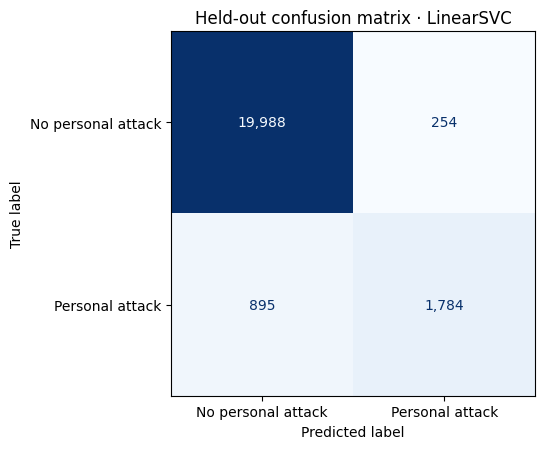

In [16]:
import json
from pathlib import Path
from time import perf_counter_ns

from IPython.display import display
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)

model_dir = Path("/content/attack_model_results")
fitting_report = json.loads((model_dir / "training_summary.json").read_text())
assert len(X_test) == len(y_test) == 22_921
assert fitting_report["training_rows"] == len(X_train) == 91_683
champion = fitting_report["champion_by_cv"]
print(f"CPU validation search and final fits: {fitting_report['wall_seconds']:.1f} seconds.")
class_ids = [0, 1]
class_names = ["No personal attack", "Personal attack"]
metric_rows, class_rows, latency_rows = [], [], []
test_predictions = test[["rev_id", "label"]].copy()

cv_summary = pd.read_csv(model_dir / "cv_summary.csv")
ngram_scores = (
    cv_summary.groupby(["model", "ngram_max"])["cv_macro_f1"].max().unstack()
    .rename(columns={1: "Unigrams", 2: "Unigrams + bigrams"})
)
print("Best validation macro F1 by feature representation")
display(ngram_scores.round(4))

latency_text = [
    "I disagree because the costs are still unclear.",
    "You never listen to what anybody else says.",
    "That argument does not address the question.",
    "Could you explain where you found that figure?",
]

for config in fitting_report["models"]:
    name = config["model"]
    pipeline = joblib.load(model_dir / config["artifact"])
    predicted = pipeline.predict(X_test)
    test_predictions[name] = predicted
    metrics = {"Model": name, "Accuracy": accuracy_score(y_test, predicted)}
    for average in ("macro", "weighted"):
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_test, predicted, labels=class_ids, average=average, zero_division=0
        )
        metrics.update({
            f"Precision ({average})": precision,
            f"Recall ({average})": recall,
            f"F1 ({average})": f1,
        })
    metric_rows.append(metrics)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, predicted, labels=class_ids, zero_division=0
    )
    for label, p, r, f, n in zip(class_names, precision, recall, f1, support):
        class_rows.append({"Model": name, "Class": label, "Precision": p, "Recall": r, "F1": f, "Support": n})

    pipeline.predict([latency_text[0]])
    timings = []
    for sample in latency_text * 10:
        start = perf_counter_ns()
        pipeline.predict([sample])
        timings.append((perf_counter_ns() - start) / 1e6)
    latency_rows.append({
        "Model": name,
        "Median warm latency (ms)": np.median(timings),
        "P95 warm latency (ms)": np.percentile(timings, 95),
    })

heldout_metrics = pd.DataFrame(metric_rows).set_index("Model")
heldout_by_class = pd.DataFrame(class_rows).set_index(["Model", "Class"])
warm_latency = pd.DataFrame(latency_rows).set_index("Model")
majority_accuracy = accuracy_score(y_test, np.full(len(y_test), y_train.mode().iloc[0]))
print(f"Held-out test: {len(y_test):,} comments. Training-majority baseline accuracy: {majority_accuracy:.2%}.")
display(heldout_metrics.round(4))
display(heldout_by_class.round(4))
display(warm_latency.round(3))

matrix = confusion_matrix(y_test, test_predictions[champion], labels=class_ids)
assert matrix.sum() == len(y_test)
print(
    f"Selected by validation: {champion}. "
    f"False positives: {matrix[0, 1]:,}. Missed personal attacks: {matrix[1, 0]:,}."
)
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(
    ax=ax, colorbar=False, cmap="Blues", values_format=",d"
)
ax.set_title(f"Held-out confusion matrix · {champion}")
fig.tight_layout()
fig.savefig(model_dir / "confusion_matrix.png", dpi=140, bbox_inches="tight")
plt.show()

heldout_metrics.to_csv(model_dir / "heldout_metrics.csv")
heldout_by_class.to_csv(model_dir / "heldout_class_metrics.csv")
warm_latency.to_csv(model_dir / "warm_latency.csv")
test_predictions.to_csv(model_dir / "heldout_predictions.csv", index=False)

In [17]:
import zipfile

export_files = [
    *(model["artifact"] for model in fitting_report["models"]),
    "training_summary.json",
    "cv_folds.csv",
    "cv_summary.csv",
    "heldout_metrics.csv",
    "heldout_class_metrics.csv",
    "heldout_predictions.csv",
    "warm_latency.csv",
    "confusion_matrix.png",
]
export_path = Path("/content/wikidetox_attack_models.zip")
with zipfile.ZipFile(export_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for name in export_files:
        archive.write(model_dir / name, name)
print(f"Export ready: {export_path.name} ({export_path.stat().st_size:,} bytes)")

Export ready: wikidetox_attack_models.zip (1,686,017 bytes)


### What the baseline results mean for the moderator

LinearSVC was selected on training cross-validation (macro F1 0.8601). On the 22,921-comment test split it reached 94.99% accuracy and 0.8642 macro F1. It produced 254 false alarms and missed 895 of 2,679 personal attacks. Logistic Regression caught a larger share of attacks (recall 83.65%) with lower alert precision (68.28%). LinearSVC's attack precision was 87.54%, and its attack recall was 66.59%.

These measurements describe the models at their standard decision rules on written Wikipedia comments. Before using the selected model for live alerts, calibrate and tune the alert threshold with training-only validation data, then audit fresh spoken examples and Manglish. The warm Python inference timings exclude speech and interface latency.

### Calibration and moderator alert threshold

LinearSVC's margin is converted to an attack probability with a fitted sigmoid. Three stratified folds on the training partition generate out-of-fold margins, so each margin comes from a model that did not fit that row. We split those margins into two disjoint pools: the first fits the sigmoid; the second picks the alert threshold. We keep the already fitted final LinearSVC as the serving estimator and reuse its saved text pipeline.

The decision rule is specified before scoring the held-out benchmark: maximize attack recall among thresholds with at least 80% precision and at least 100 flagged comments on the threshold-selection pool. If no threshold satisfies both, select the highest training-validation macro F1 among thresholds with at least 100 flags. The 80% precision target is a prototype design choice. The locked threshold is evaluated once on the test benchmark. The score reflects the written corpus and requires an audit on live speech.

In [18]:
from pathlib import Path
import json
from time import perf_counter

from IPython.display import display
import joblib
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from threadpoolctl import threadpool_limits

model_dir = Path("/content/attack_model_results")
model_path = model_dir / "LinearSVC.joblib"
assert model_path.is_file(), "Restore the saved LinearSVC artifact or rerun the training cells"
assert len(train) == 91_683, "Run the preparation cells to restore the training partition"

alert_pipeline = joblib.load(model_path)
assert alert_pipeline.classes_.tolist() == [0, 1]
train_labels = train["label"].to_numpy()
fit_template = clone(alert_pipeline).set_params(tfidf__preprocessor=None)
folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=377)
start = perf_counter()
print("Building three out-of-fold margin sets from training data.", flush=True)
with threadpool_limits(limits=1):
    oof_margins = cross_val_predict(
        fit_template, train["model_text"].to_numpy(), train_labels,
        cv=folds, method="decision_function", n_jobs=1,
    )
assert oof_margins.shape == train_labels.shape and np.isfinite(oof_margins).all()
cal_idx, val_idx = train_test_split(
    np.arange(len(train)), test_size=0.5, stratify=train_labels, random_state=378
)
assert set(cal_idx).isdisjoint(val_idx)

sigmoid = LogisticRegression(C=1000, max_iter=1000)
sigmoid.fit(oof_margins[cal_idx, None], train_labels[cal_idx])
assert sigmoid.classes_.tolist() == [0, 1] and sigmoid.coef_[0, 0] > 0
validation_probabilities = sigmoid.predict_proba(oof_margins[val_idx, None])[:, 1]
validation_labels = train_labels[val_idx]

def attack_metrics(actual, predicted):
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    return {
        "Attack precision": float(tp / max(1, tp + fp)),
        "Attack recall": float(tp / max(1, tp + fn)),
        "Macro F1": f1_score(actual, predicted, average="macro", zero_division=0),
        "Alerts": int(tp + fp),
        "False alarms": int(fp),
        "Missed attacks": int(fn),
    }

target_precision = 0.80
minimum_alerts = 100
threshold_grid = np.arange(1, 100) / 100
candidates = pd.DataFrame([
    {"Threshold": float(cutoff), **attack_metrics(validation_labels, validation_probabilities >= cutoff)}
    for cutoff in threshold_grid
])
candidate_pool = candidates[candidates["Alerts"] >= minimum_alerts]
assert not candidate_pool.empty, "No threshold produced enough validation alerts"
eligible = candidate_pool[candidate_pool["Attack precision"] >= target_precision]
if eligible.empty:
    best = candidate_pool.sort_values(["Macro F1", "Attack precision", "Threshold"], ascending=False).iloc[0]
    selection_basis = "Highest validation macro F1; precision target was not achieved."
else:
    best = eligible.sort_values(["Attack recall", "Attack precision", "Threshold"], ascending=False).iloc[0]
    selection_basis = "Highest validation recall subject to at least 80% attack precision."

alert_threshold = float(best["Threshold"])
baseline_validation = attack_metrics(validation_labels, oof_margins[val_idx] >= 0)
validation_summary = pd.DataFrame([
    {"Rule": "Original SVC decision", **baseline_validation},
    {"Rule": f"Alert at probability >= {alert_threshold:.2f}", **attack_metrics(
        validation_labels, validation_probabilities >= alert_threshold
    )},
]).set_index("Rule")
validation_brier = brier_score_loss(validation_labels, validation_probabilities)
alert_policy = {
    "probability_threshold": alert_threshold,
    "validation_precision_target": target_precision,
    "validation_minimum_alerts": minimum_alerts,
    "selection_basis": selection_basis,
    "calibration_rows": len(cal_idx),
    "threshold_validation_rows": len(val_idx),
    "out_of_fold_seed": 377,
    "split_seed": 378,
    "validation_brier_loss": validation_brier,
}
joblib.dump(
    {"pipeline": alert_pipeline, "sigmoid": sigmoid, "threshold": alert_threshold},
    model_dir / "LinearSVC_alert.joblib",
    compress=3,
)
(model_dir / "alert_policy.json").write_text(json.dumps(alert_policy, indent=2) + "\n")
candidates.to_csv(model_dir / "validation_thresholds.csv", index=False)

print(f"Calibration rows: {len(cal_idx):,}; threshold-selection rows: {len(val_idx):,}.")
print(f"Locked alert threshold: {alert_threshold:.2f}. {selection_basis}")
print(f"Training-validation Brier loss: {validation_brier:.4f}. Elapsed: {perf_counter() - start:.1f}s.")
display(validation_summary.round(4))

Building three out-of-fold margin sets from training data.
Calibration rows: 45,841; threshold-selection rows: 45,842.
Locked alert threshold: 0.35. Highest validation recall subject to at least 80% attack precision.
Training-validation Brier loss: 0.0396. Elapsed: 91.5s.


,Attack precision,Attack recall,Macro F1,Alerts,False alarms,Missed attacks
Rule,,,,,,
Original SVC decision,0.8705,0.6451,0.8559,3970,514,1901
Alert at probability >= 0.35,0.8021,0.7288,0.8670,4867,963,1453


,Attack precision,Attack recall,Macro F1,Alerts,False alarms,Missed attacks
Rule,,,,,,
Original SVC decision,0.8754,0.6659,0.8642,2038,254,895
Calibrated alert >= 0.35,0.8037,0.7413,0.8712,2471,485,693


Locked benchmark: 22,921 comments; Brier loss 0.0384.


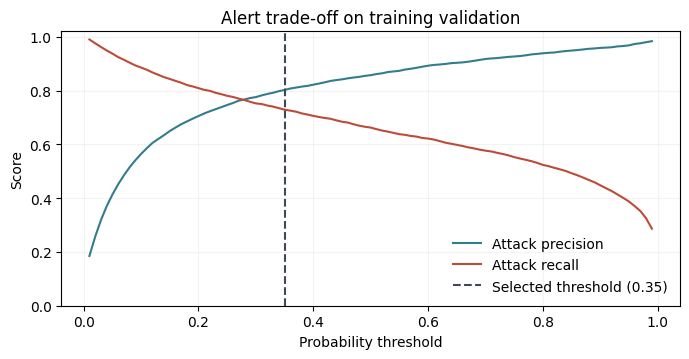

In [19]:
import matplotlib.pyplot as plt

alert_bundle = joblib.load(model_dir / "LinearSVC_alert.joblib")
assert alert_bundle["threshold"] == alert_threshold
test_margins = alert_bundle["pipeline"].decision_function(X_test)
test_probabilities = alert_bundle["sigmoid"].predict_proba(test_margins[:, None])[:, 1]
base_predictions = (test_margins > 0).astype("int8")
alert_predictions = (test_probabilities >= alert_bundle["threshold"]).astype("int8")
base_saved = pd.read_csv(model_dir / "heldout_predictions.csv")
assert base_saved["rev_id"].tolist() == test["rev_id"].tolist()
assert base_saved["LinearSVC"].tolist() == base_predictions.tolist()
assert len(y_test) == 22_921

alert_benchmark = pd.DataFrame([
    {"Rule": "Original SVC decision", **attack_metrics(y_test, base_predictions)},
    {"Rule": f"Calibrated alert >= {alert_threshold:.2f}", **attack_metrics(y_test, alert_predictions)},
]).set_index("Rule")
display(alert_benchmark.round(4))
test_brier = brier_score_loss(y_test, test_probabilities)
print(f"Locked benchmark: {len(y_test):,} comments; Brier loss {test_brier:.4f}.")
alert_benchmark.to_csv(model_dir / "alert_benchmark.csv")
alert_test_rows = test[["rev_id", "label"]].assign(
    baseline_prediction=base_predictions,
    alert_prediction=alert_predictions,
    attack_probability=test_probabilities,
)
alert_test_rows.to_csv(model_dir / "alert_benchmark_predictions.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.7))
ax.plot(candidates["Threshold"], candidates["Attack precision"], color="#327d8d", label="Attack precision")
ax.plot(candidates["Threshold"], candidates["Attack recall"], color="#bc4c37", label="Attack recall")
ax.axvline(alert_threshold, color="#41475a", linestyle="--", label=f"Selected threshold ({alert_threshold:.2f})")
ax.set(xlabel="Probability threshold", ylabel="Score", ylim=(0, 1.02),
       title="Alert trade-off on training validation")
ax.legend(frameon=False)
ax.grid(alpha=0.15)
fig.tight_layout()
fig.savefig(model_dir / "alert_threshold_tradeoff.png", dpi=140, bbox_inches="tight")
plt.show()

### Paired Manglish probe

These 20 authored pairs share a reference label within each pair. We compare one standard English phrasing with a Manglish-style phrasing that uses particles such as “lah,” “ya,” and “ah,” or local informal syntax. The pairs cover clear direct insults and ordinary disagreement, requests, and interruptions. They are a small diagnostic probe. They were not used to fit or tune the model, and they do not establish population fairness. Native-speaker review and natural recordings are still needed.

In [20]:
paired_examples = [
    (0, "I disagree because that estimate is too high.", "I disagree lah, that estimate too high."),
    (0, "Could you repeat the last point?", "Can repeat the last point ah?"),
    (0, "The spreadsheet does not support that claim.", "The spreadsheet does not support that claim lah."),
    (0, "I don't think the proposal is ready yet.", "I don't think the proposal ready yet lah."),
    (0, "Please wait until she finishes speaking.", "Wait until she finishes speaking first lah."),
    (0, "The argument is weak because the source is too old.", "The argument weak lah, the source is too old."),
    (0, "Can you give me one more example?", "Can give me one more example ah?"),
    (0, "You can post the numbers later.", "You can post the numbers later lah."),
    (0, "I never said you were wrong.", "I never said you were wrong ya."),
    (0, "I understand your point, but I see it differently.", "I get your point lah, but I see it differently."),
    (1, "You are a stupid idiot.", "You are a stupid idiot lah."),
    (1, "Nobody wants to hear you talk because you are useless.", "Nobody wants to hear you talk, you useless lah."),
    (1, "You are too dumb to understand this.", "You too dumb to understand this lah."),
    (1, "You are such a pathetic loser.", "You are really a pathetic loser lah."),
    (1, "You are a liar and a coward.", "You are a liar and a coward lah."),
    (1, "Only an idiot like you would believe that.", "Only an idiot like you would believe that lah."),
    (1, "You have no brain.", "You got no brain ah?"),
    (1, "You are worthless, so shut up.", "You are worthless lah, just shut up."),
    (1, "You are the most incompetent person here.", "You are the most incompetent person here lah."),
    (1, "You are a piece of garbage.", "You are a piece of garbage lah."),
]
dialect_audit = pd.DataFrame(paired_examples, columns=["Reference", "Standard English", "Manglish style"])
dialect_audit.index = np.arange(1, len(dialect_audit) + 1)
dialect_audit.index.name = "Pair"
dialect_rows = []
for variant in ("Standard English", "Manglish style"):
    margins = alert_bundle["pipeline"].decision_function(dialect_audit[variant])
    probabilities = alert_bundle["sigmoid"].predict_proba(margins[:, None])[:, 1]
    predictions = (probabilities >= alert_threshold).astype("int8")
    dialect_audit[f"{variant} probability"] = probabilities
    dialect_audit[f"{variant} alert"] = predictions
    dialect_rows.append({"Variant": variant, **attack_metrics(dialect_audit["Reference"], predictions)})

standard_alerts = dialect_audit["Standard English alert"]
manglish_alerts = dialect_audit["Manglish style alert"]
dialect_audit["Decision changed"] = standard_alerts.ne(manglish_alerts)
dialect_audit["Score difference"] = dialect_audit["Manglish style probability"] - dialect_audit["Standard English probability"]
dialect_summary = pd.DataFrame(dialect_rows).set_index("Variant")
print(f"{len(dialect_audit)} pairs; {dialect_audit['Decision changed'].sum()} changed alert decisions.")
display(dialect_summary.round(3))
display(dialect_audit.round(3))
dialect_summary.to_csv(model_dir / "manglish_audit_summary.csv")
dialect_audit.to_csv(model_dir / "manglish_audit_pairs.csv")

20 pairs; 1 changed alert decisions.


,Attack precision,Attack recall,Macro F1,Alerts,False alarms,Missed attacks
Variant,,,,,,
Standard English,1.0,0.9,0.950,9,0,1
Manglish style,1.0,0.8,0.899,8,0,2


,Reference,Standard English,Manglish style,Standard English probability,Standard English alert,Manglish style probability,Manglish style alert,Decision changed,Score difference
Pair,,,,,,,,,
1,0,I disagree because that estimate is too high.,"I disagree lah, that estimate too high.",0.004,0,0.009,0,False,0.005
2,0,Could you repeat the last point?,Can repeat the last point ah?,0.006,0,0.003,0,False,-0.002
3,0,The spreadsheet does not support that claim.,The spreadsheet does not support that claim lah.,0.002,0,0.002,0,False,0.000
4,0,I don't think the proposal is ready yet.,I don't think the proposal ready yet lah.,0.021,0,0.021,0,False,0.000
5,0,Please wait until she finishes speaking.,Wait until she finishes speaking first lah.,0.034,0,0.055,0,False,0.021
6,0,The argument is weak because the source is too...,"The argument weak lah, the source is too old.",0.002,0,0.002,0,False,0.000
7,0,Can you give me one more example?,Can give me one more example ah?,0.040,0,0.008,0,False,-0.032
8,0,You can post the numbers later.,You can post the numbers later lah.,0.014,0,0.014,0,False,0.000
9,0,I never said you were wrong.,I never said you were wrong ya.,0.010,0,0.021,0,False,0.010


In [22]:
import re

error_observations = {
    113705916: "Profanity expresses frustration about missing images. The message does not target a person.",
    598982942: "A proposed instruction to the addressee quotes a hypothetical dismissal of the speaker. The offensive phrase appears in a different role from a direct attack.",
    30234746: "An explicit insult is followed by a question about an article. The full-turn score may underweight the short attack.",
    445225443: "The isolated wording resembles a request. If the remark is mocking, prior turns or delivery would help resolve it. The crowd label is ambiguous without that context.",
}

def redact_for_review(text):
    text = text.replace("NEWLINE_TOKEN", " ").replace("TAB_TOKEN", " ")
    text = re.sub(r"https?://\S+|www\.\S+", "[link]", text, flags=re.I)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b", "[email]", text)
    text = re.sub(r"\b(?:\d{1,3}\.){3}\d{1,3}\b", "[IP]", text)
    text = re.sub(r"(?:user(?: talk)?|special:contributions):[^\]\s|]+", "[user]", text, flags=re.I)
    return re.sub(r"\s+", " ", text).strip()[:185]

chosen_errors = (
    alert_test_rows.set_index("rev_id").loc[list(error_observations)]
    .join(test.set_index("rev_id")[["comment"]])
    .join(data.set_index("rev_id")[["attack_votes", "ratings"]])
)
assert len(chosen_errors) == 4
assert chosen_errors["label"].ne(chosen_errors["alert_prediction"]).all()
assert chosen_errors["label"].value_counts().to_dict() == {0: 2, 1: 2}

tfidf = alert_bundle["pipeline"].named_steps["tfidf"]
feature_names = tfidf.get_feature_names_out()
coefficients = alert_bundle["pipeline"].named_steps["classifier"].coef_[0]
sparse_rows = tfidf.transform(chosen_errors["comment"])

def strongest_terms(sparse_row, positive):
    contributions = sparse_row.data * coefficients[sparse_row.indices]
    order = np.argsort(-contributions if positive else contributions)
    selected = [i for i in order if (contributions[i] > 0 if positive else contributions[i] < 0)]
    return ", ".join(feature_names[sparse_row.indices[i]] for i in selected[:3])

error_table = pd.DataFrame([
    {
        "Error": "Missed attack" if row.label else "False alarm",
        "Score": row.attack_probability,
        "Attack votes": f"{row.attack_votes}/{row.ratings}",
        "Excerpt": redact_for_review(row.comment),
        "Top cues toward error": strongest_terms(sparse_rows[i], positive=not row.label),
        "Possible explanation": error_observations[row.Index],
    }
    for i, row in enumerate(chosen_errors.itertuples())
], index=chosen_errors.index)
display(error_table.round(3))

changed_pairs = dialect_audit.loc[dialect_audit["Decision changed"], [
    "Standard English", "Manglish style", "Reference", "Standard English probability",
    "Manglish style probability", "Standard English alert", "Manglish style alert",
]]
print("Paired probe decisions that changed")
display(changed_pairs.round(3))
error_table.to_csv(model_dir / "alert_error_analysis.csv")

,Error,Score,Attack votes,Excerpt,Top cues toward error,Possible explanation
rev_id,,,,,,
113705916,False alarm,0.365,4/10,Where the hell did all the images go????,"hell, go, the imag",Profanity expresses frustration about missing ...
598982942,False alarm,0.368,7/19,:I should stay at Wikisource where I cant hurt...,"piss off, piss, off",A proposed instruction to the addressee quotes...
30234746,Missed attack,0.095,8/10,You are insane. What is wrong with writing an ...,"write an, what is, articl",An explicit insult is followed by a question a...
445225443,Missed attack,0.060,10/19,::Next time you feel you need a break perhaps ...,"feel you, you feel, a break",The isolated wording resembles a request. If t...


Paired probe decisions that changed


,Standard English,Manglish style,Reference,Standard English probability,Manglish style probability,Standard English alert,Manglish style alert
Pair,,,,,,,
17,You have no brain.,You got no brain ah?,1,0.737,0.067,1,0


### Implications for live moderation

At the locked 0.35 threshold, the benchmark found 202 additional attacks and produced 231 additional false alarms. Attack precision was 80.37% and recall was 74.13%. This is the operating point to try in the moderator prototype. An alert requests human review.

The error examples show the cost of treating an isolated utterance as a full conversation. Profanity, reported speech, crowd disagreement and missing conversational context affect the result. On the paired probe, the reference attack “You have no brain” triggered an alert, while “You got no brain ah?” did not. The small diagnostic below separates the word swap from the added particle. It is a single case, and the 20 authored pairs provide no estimate of fairness in the population.

The notebook masks URLs, account markers, emails and IPs in the selected examples when present. In the live prototype, audio sent to a cloud transcription provider must be disclosed to participants. The planned default is to avoid saving raw audio and restrict review of excerpts to the moderator. Probability calibration and a human review step reduce the risk of acting on a single prediction.

In [23]:
import zipfile

probe_texts = [
    "You have no brain.",
    "You have no brain ah?",
    "You got no brain.",
    "You got no brain ah?",
]
probe_margins = alert_bundle["pipeline"].decision_function(probe_texts)
probe_probabilities = alert_bundle["sigmoid"].predict_proba(probe_margins[:, None])[:, 1]
dialect_detail = pd.DataFrame({
    "Text": probe_texts,
    "Attack probability": probe_probabilities,
    "Alert": probe_probabilities >= alert_threshold,
})
display(dialect_detail.round(3))
dialect_detail.to_csv(model_dir / "manglish_single_case_probe.csv", index=False)

alert_export_files = [
    "LinearSVC_alert.joblib", "alert_policy.json", "validation_thresholds.csv",
    "alert_benchmark.csv", "alert_benchmark_predictions.csv", "alert_threshold_tradeoff.png",
    "alert_error_analysis.csv", "manglish_audit_pairs.csv", "manglish_audit_summary.csv",
    "manglish_single_case_probe.csv",
]
alert_export = Path("/content/wikidetox_alert_evaluation.zip")
with zipfile.ZipFile(alert_export, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for name in alert_export_files:
        archive.write(model_dir / name, name)
print(f"Alert export ready: {alert_export.name} ({alert_export.stat().st_size:,} bytes).")

,Text,Attack probability,Alert
0,You have no brain.,0.737,True
1,You have no brain ah?,0.199,False
2,You got no brain.,0.232,False
3,You got no brain ah?,0.067,False


Alert export ready: wikidetox_alert_evaluation.zip (967,094 bytes).
